## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.00334ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.27s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
/model created.
00: Trainer for 'AEC train_sqrtVar_sqrtVar_linattn [acaee5f1ce9f88de]' on data acaee5f1ce9f88de
00: ===========================================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_sqrtVar_linattn b87a14bd/last.pt'... checkpoint version '<unknown>' does not match model version '1' - restarting experiment.
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_sqrtVar_linattn b87a14bd/.
00: Launching 'AEC train_sqrtVar_sqrtVar_linattn [acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 256 for valuation. The model has 44849 parameters.
00: Training 'train_sqrtVar_sqrtVar_linattn' epoch 1/1000 er

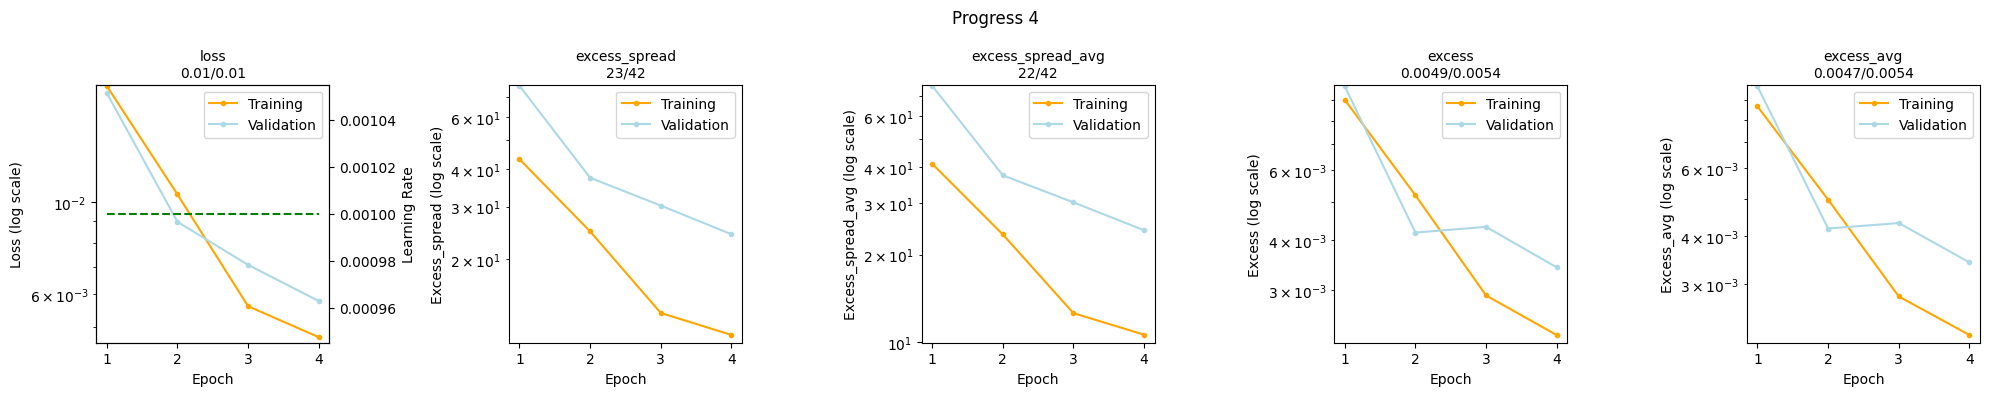

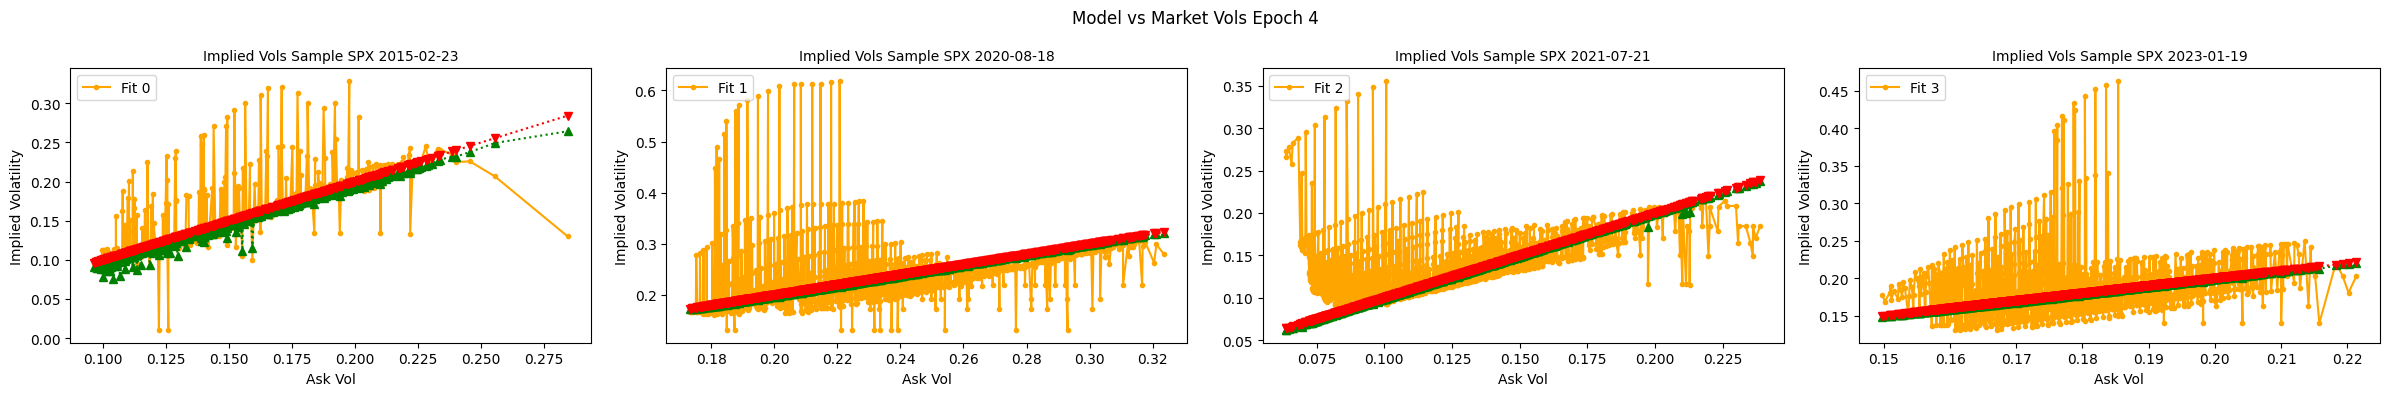

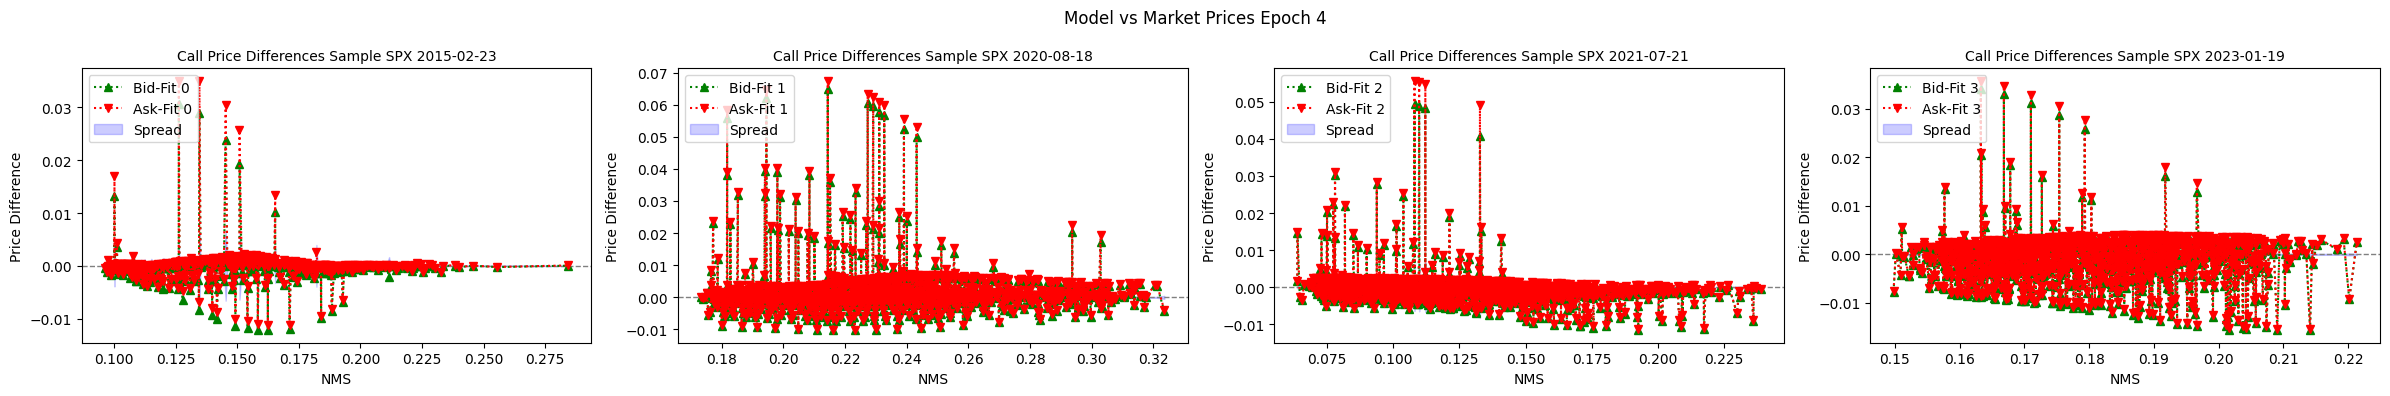

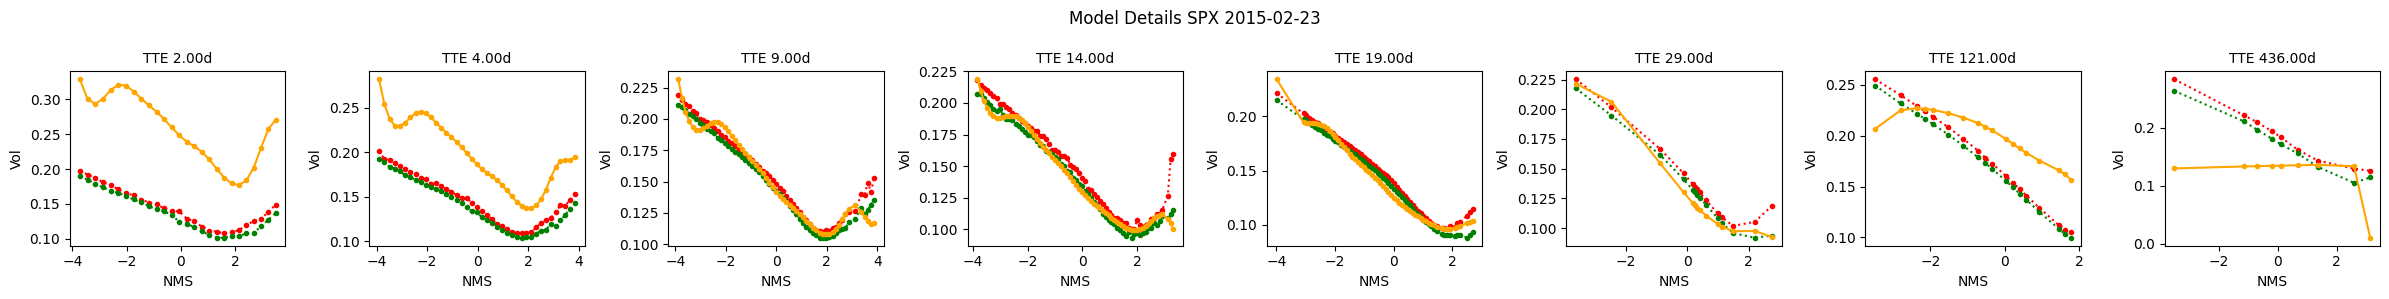

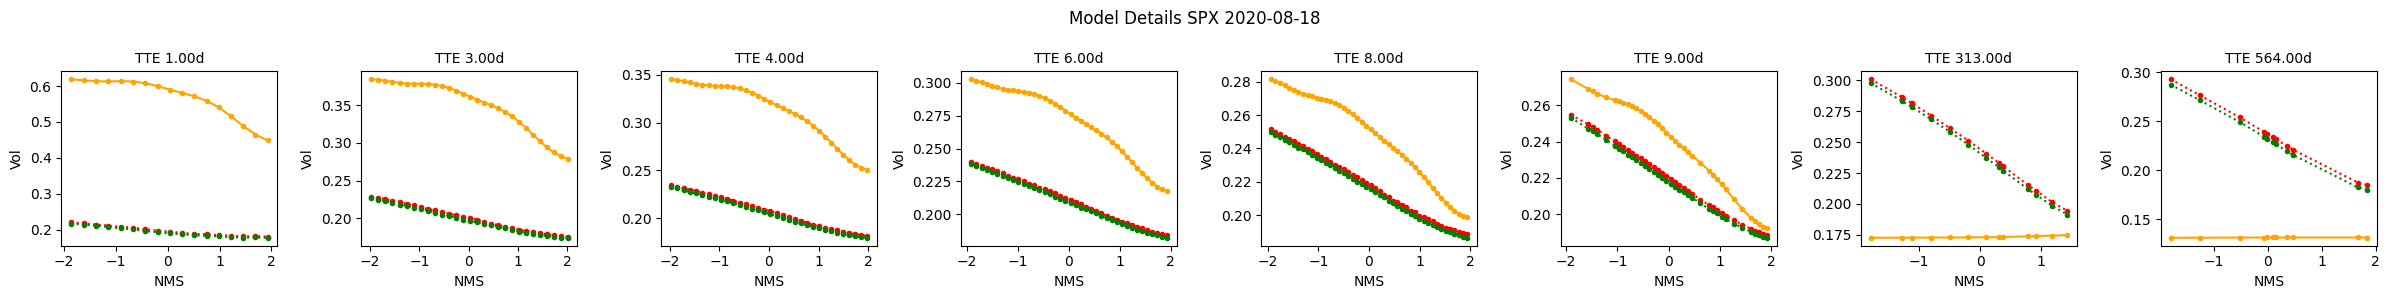

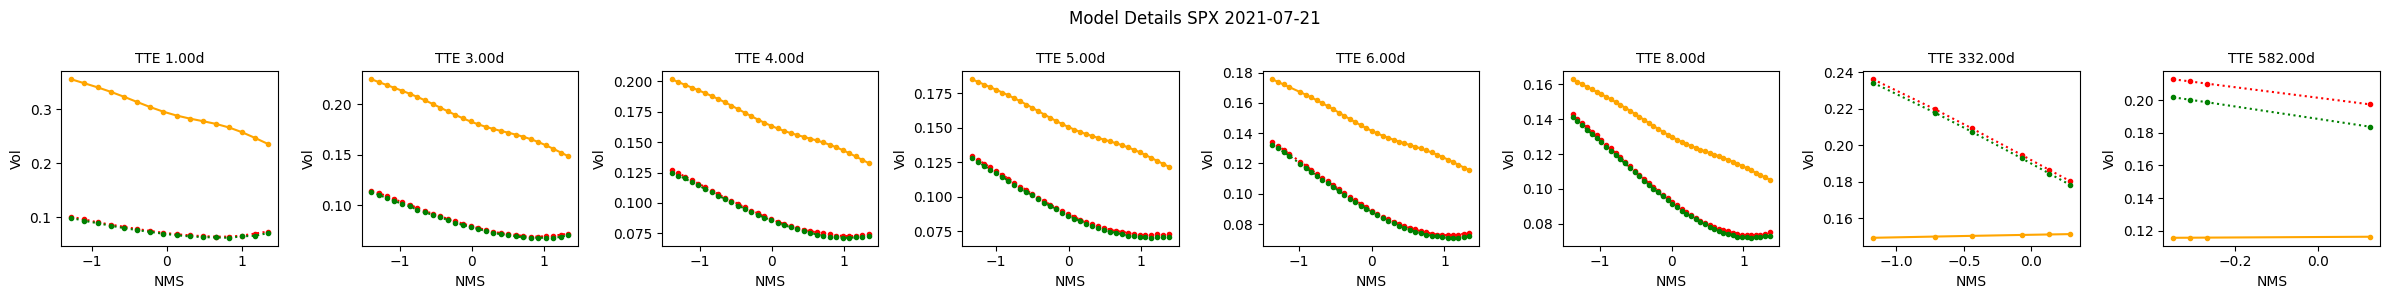

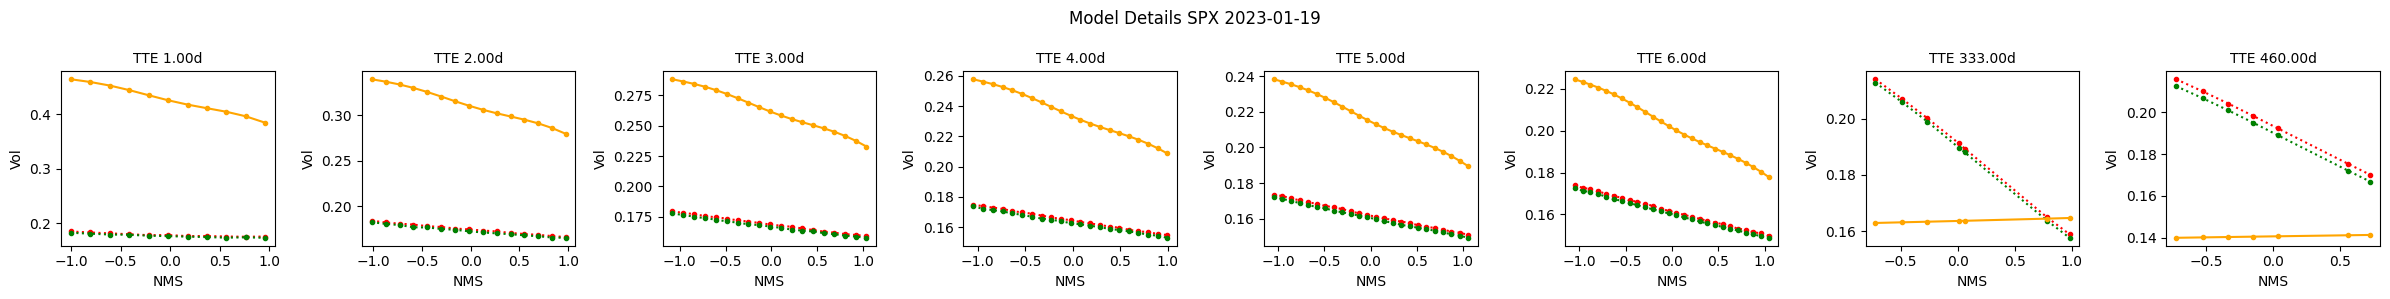

01:   Epoch 1: Saving new best validation loss 0.01836 to '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_sqrtVar_linattn b87a14bd/best.pt'... done; this took 0.047s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_sqrtVar_linattn b87a14bd/last.pt... done; this took 0.032s.
00: Training 'train_sqrtVar_sqrtVar_linattn' epoch 2/1000 error avg trn 0.01575; val 0.01045/0.008974 [2:57 2s 0.73s]. LR: 1.00e-03, GN 0.001605, excess_weighted: 0.003128/0.003601, excess_weighted_avg: 0.003493/0.0038, excess_spread: 24.79/37.49, excess_spread_avg: 23.48/37.49, excess: 0.005192/0.004185, excess_avg: 0.004971/0.004185. ETA: 101:16:41.
01:   Epoch 2: Saving new best validation loss 0.008974 vs. 0.01836 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_sqrtVar_linattn b87a14bd/best.pt'... done; this took 0.049s.
01:   Saving checkpoint to /media/sto

In [ ]:
from quantdata.dysanos.simple.model import DeepSetEncoderFactory, AttentionDecoderFactory, SimpleDecoderFactory, AttentionEncoderFactory
from quantdata.dysanos.simple.aec import run, ipynbname, AEC, FeedForward

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "sqrtVar",
    fit_what    = "sqrtVar",
    num_state   = 64,
    fit_average = True,

    # rarely touch these
    weight_by_spread = True,
    max_weight = 100.,
    mid_fit_weight = 0.1,

    encoder = AttentionEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 0, # linear
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 0,  # linear
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = AttentionDecoderFactory(
        num_head = 16,
        num_QK = 4,        
        V_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',    
        ),
        QK_config = FeedForward.Config(
            num_depth = 0, # linear
            num_width = 4, # equal QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',
        )
    ),
)

run( ipynbname.name(), version="1.1", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=256 )
